# Exploratory Data Analysis: Fantasy Football
## CSCI 5502 - Milestone 2

### Objective

This notebook explores historical NFL fantasy football data from
the 2025 season.

Our goals are to:
- Understand the distribution of fantasy points.
- Examine differences across player positions.
- Compare projected and actual fantasy points.
- Investigate weekly performance trends.
- Identify missing values, inconsistencies, and possible outliers.

Missing values will be preserved during the initial exploration.
We will investigate them before deciding whether to remove,
impute, or retain them.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import random

# Project directory
root = Path.cwd().parent

# Load the original dataset
df = pd.read_csv(root / "data" / "final_2025.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7572, 80)


,Unnamed: 0,player_id,player,position,team,season,week,eventId,opponent,atVs,...,location,espn,game_id,gameday,gametime,stadium,roof,surface,temp,wind
0,0,4429795,Jahmyr Gibbs,RB,DET,2025,18,401772965,CHI,away,...,"Chicago, IL",401772965,2025_18_DET_CHI,2026-01-04,16:25,Soldier Field,outdoors,grass,33.0,4.0
1,1,4429795,Jahmyr Gibbs,RB,DET,2025,17,401772711,MIN,away,...,"Minneapolis, MN",401772711,2025_17_DET_MIN,2025-12-25,16:30,U.S. Bank Stadium,dome,sportturf,70.0,NaN
2,2,4429795,Jahmyr Gibbs,RB,DET,2025,16,401772806,PIT,home,...,"Detroit, MI",401772806,2025_16_PIT_DET,2025-12-21,16:25,Ford Field,dome,fieldturf,70.0,NaN
3,3,4429795,Jahmyr Gibbs,RB,DET,2025,15,401772909,LAR,away,...,"Inglewood, CA",401772909,2025_15_DET_LA,2025-12-14,16:25,SoFi Stadium,dome,matrixturf,70.0,NaN
4,4,4429795,Jahmyr Gibbs,RB,DET,2025,14,401772947,DAL,home,...,"Detroit, MI",401772947,2025_14_DAL_DET,2025-12-04,20:15,Ford Field,dome,fieldturf,70.0,NaN


In [27]:
print("Unique players:", df["player_id"].nunique())
print("Unique weeks:", df["week"].nunique())

print("\nRecords by position:")
display(df["position"].value_counts())

print("\nMissing values:")
display(df.isna().sum())

print("\nSummary statistics:")
display(df.describe())

Unique players: 685
Unique weeks: 18

Records by position:


position
WR    2806
RB    1808
TE    1739
QB     676
K      543
Name: count, dtype: int64


Missing values:


Unnamed: 0       0
player_id        0
player           0
position         0
team             0
              ... 
stadium          0
roof             0
surface         27
temp          1249
wind          2633
Length: 80, dtype: int64


Summary statistics:


,Unnamed: 0,player_id,season,week,eventId,rushingAttempts,rushingYards,yardsPerRushAttempt,rushingTouchdowns,longRushing,...,fieldGoalsMade,fieldGoalAttempts,extraPointsMade,extraPointAttempts,opp_def_rank,fantasy_points,projected_points,espn,temp,wind
count,7572.000000,7.572000e+03,7572.0,7572.000000,7.572000e+03,7023.000000,7023.000000,7023.000000,7023.000000,7023.000000,...,543.000000,543.000000,543.000000,543.000000,7572.000000,7572.000000,7281.000000,7.572000e+03,6323.000000,4939.000000
mean,3785.500000,3.967996e+06,2025.0,9.499208,4.017728e+08,2.078172,9.063506,1.350776,0.072619,3.421615,...,1.714549,2.003683,2.228361,2.322284,16.545827,6.526960,6.948332,4.017728e+08,61.176182,7.866572
std,2185.992452,1.012643e+06,0.0,5.293262,8.682401e+01,4.594061,22.735785,3.005645,0.312778,8.022528,...,1.246956,1.323916,1.439867,1.445569,9.213211,7.599769,5.911628,8.682401e+01,16.654850,4.456238
min,0.000000,5.529000e+03,2025.0,1.000000,4.017725e+08,0.000000,-14.000000,-10.000000,0.000000,-10.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,-3.060000,0.000000,4.017725e+08,8.000000,0.000000
25%,1892.750000,3.917914e+06,2025.0,5.000000,4.017728e+08,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,9.000000,0.000000,1.648295,4.017728e+08,51.000000,5.000000
50%,3785.500000,4.361106e+06,2025.0,10.000000,4.017728e+08,0.000000,0.000000,0.000000,0.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,17.000000,3.920000,6.218530,4.017728e+08,66.000000,7.000000
75%,5678.250000,4.431487e+06,2025.0,14.000000,4.017729e+08,1.000000,4.000000,2.000000,0.000000,3.000000,...,2.000000,3.000000,3.000000,3.000000,25.000000,10.100000,10.808601,4.017729e+08,70.000000,10.000000
max,7571.000000,5.208518e+06,2025.0,18.000000,4.017730e+08,36.000000,244.000000,65.000000,4.000000,93.000000,...,6.000000,6.000000,7.000000,7.000000,32.000000,55.400000,27.880636,4.017730e+08,89.000000,20.000000


## 2. Fantasy Score Categories

We categorize fantasy scores into four groups:

- Missing (NaN)
- Zero
- Negative
- Positive

This allows us to investigate missing and zero values
separately without modifying the original fantasy scores.

In [28]:
df["score_category"] = np.select(
    [
        df["fantasy_points"].isna(),
        df["fantasy_points"] == 0,
        df["fantasy_points"] < 0,
        df["fantasy_points"] > 0
    ],
    [
        "Missing (NaN)",
        "Zero",
        "Negative",
        "Positive"
    ],
    default="Unknown"
)

# Count observations in each category
score_counts = df["score_category"].value_counts()

display(score_counts)

# Calculate percentages
score_percent = (
    df["score_category"]
    .value_counts(normalize=True) * 100
).round(2)

display(score_percent)

score_category
Positive    5442
Zero        2043
Negative      87
Name: count, dtype: int64

score_category
Positive    71.87
Zero        26.98
Negative     1.15
Name: proportion, dtype: float64

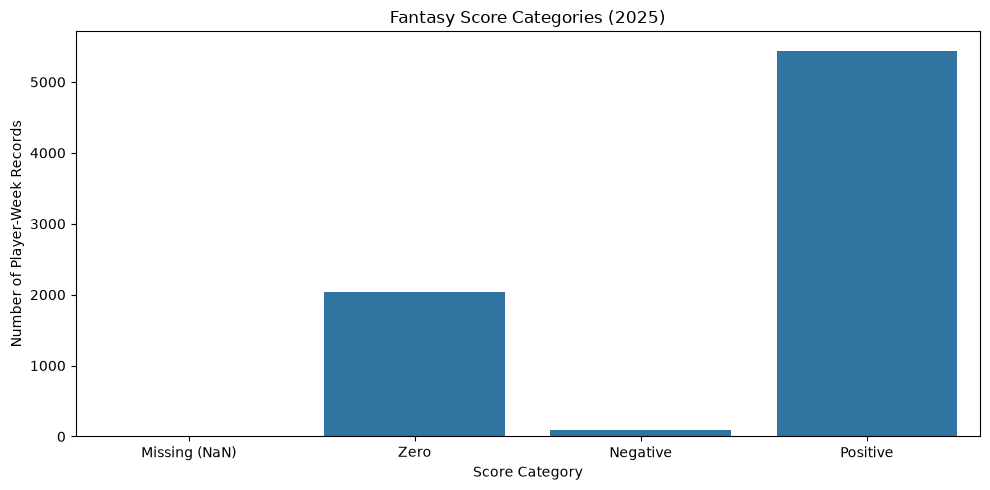

In [29]:
plt.figure(figsize=(10, 5))

order = ["Missing (NaN)", "Zero", "Negative", "Positive"]

sns.countplot(
    data=df,
    x="score_category",
    order=order
)

plt.title("Fantasy Score Categories (2025)")
plt.xlabel("Score Category")
plt.ylabel("Number of Player-Week Records")

plt.tight_layout()
plt.show()

In [30]:
# Count each score category
counts = df["score_category"].value_counts()

# Calculate percentage of total records
percentages = (
    df["score_category"].value_counts(normalize=True) * 100
).round(2)

# Combine into a table
summary = pd.DataFrame({
    "Count": counts,
    "Percentage (%)": percentages
})

display(summary)

,Count,Percentage (%)
score_category,,
Positive,5442,71.87
Zero,2043,26.98
Negative,87,1.15


### Interpretation

The dataset contains 13,958 player-week records from the 2025 NFL season. Approximately 42% of records have positive fantasy scores, while another 41.5% have scores of exactly zero. About 15.1% of records have missing fantasy scores, and only 1.2% have negative scores.

The large proportion of zero scores suggests that many player-week observations have little or no recorded fantasy production. However, we cannot determine whether these players participated in games based on fantasy points alone.

We will retain missing values during EDA and investigate them further before deciding how to handle them during preprocessing.

In [31]:
# Count each score category by position
position_counts = pd.crosstab(
    df["position"],
    df["score_category"]
)

# Calculate percentages within each position
position_percent = (
    position_counts.div(
        position_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

display(position_percent)

score_category,Negative,Positive,Zero
position,,,
K,0.55,96.32,3.13
QB,6.36,89.50,4.14
RB,1.05,75.33,23.62
TE,0.17,59.34,40.48
WR,0.68,68.42,30.90


In [32]:
print("Dataset shape:", df.shape)

print("\nMissing fantasy points:")
print(df["fantasy_points"].isna().sum())

print("\nScore categories:")
print(df["score_category"].value_counts(dropna=False))

print("\nPositions:")
print(df["position"].value_counts())

Dataset shape: (7572, 81)

Missing fantasy points:
0

Score categories:
score_category
Positive    5442
Zero        2043
Negative      87
Name: count, dtype: int64

Positions:
position
WR    2806
RB    1808
TE    1739
QB     676
K      543
Name: count, dtype: int64


Now we are going to generate a statistic called $d$ which will be the raw difference between the projected points and the actual points. We will use this statistic to determine if the projections have any biases in direction, and we will evaluate this difference across all positions. 

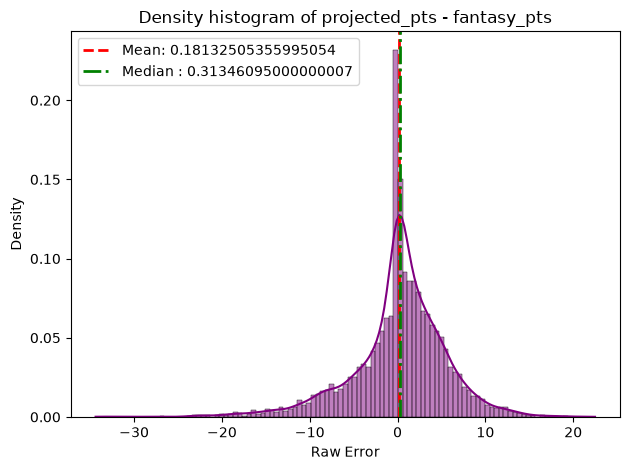

In [33]:
df["d"] = df["projected_points"] - df["fantasy_points"]

# df.head()

positions = df["position"].unique().tolist()

avg = df["d"].mean()
med = df["d"].median()

ax = sns.histplot(df, x = "d", kde=True, color="purple", stat="density")
plt.title("Density histogram of projected_pts - fantasy_pts")

plt.axvline(
    avg,
    color="red",
    linestyle="--",
    linewidth=2,
    label = f"Mean: {avg}"
    
)
plt.axvline(
    med,
    color="green",
    linestyle="-.",
    linewidth=2,
    label = f"Median : {med}"
    
)

plt.xlabel("Raw Error")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()

plt.show()

### Interpretation:
We can see that the distribution is slightly negative skewed with $\tilde{X} > \bar{X}$ indication a negative skew, but it is approaching a normal distribution centered on 0. This indicates that our projection biased is only slightly more biased in the positive direction as in oversetimating the projections.

## Now lets compare these differences across each position

In [43]:

def generate_plot(df, pos):
    
    filtered_df = df[df["position"] == pos]["d"]

    mean_val = filtered_df.mean()
    med_val =  filtered_df.median()
    #generate random color
    random_color = f"#{random.randint(0, 0xFFFFFF):06x}"

    ax = sns.histplot(df, x = "d", kde=True, color=random_color, stat="density")
    plt.title(f"Density histogram of projected_pts - fantasy_pts of postion: {pos}")

    plt.axvline(
        avg,
        color="red",
        linestyle="--",
        linewidth=2,
        label = f"Mean: {mean_val}"
        
    )
    plt.axvline(
        med,
        color="green",
        linestyle="-.",
        linewidth=2,
        label = f"Median : {med_val}"
        
    )

    plt.xlabel("Raw Error : d")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()

    plt.show()
    


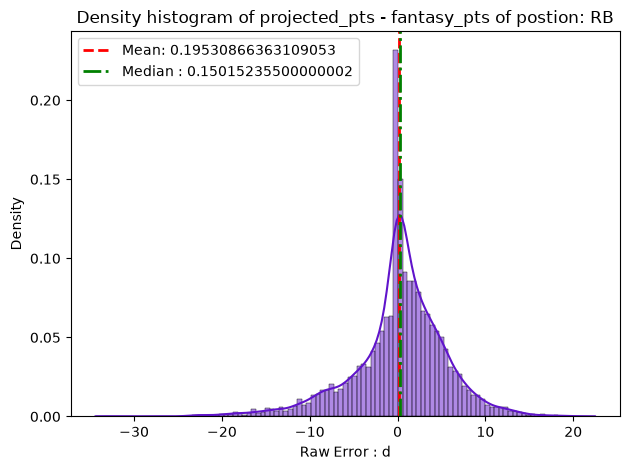

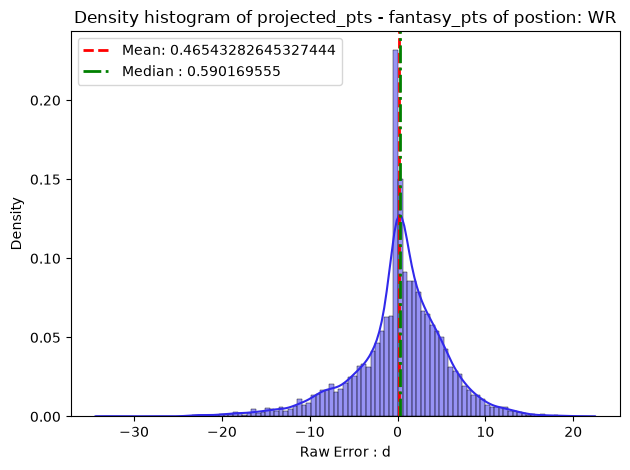

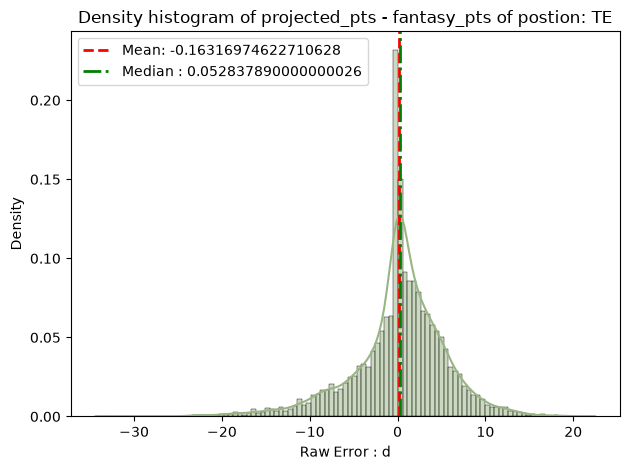

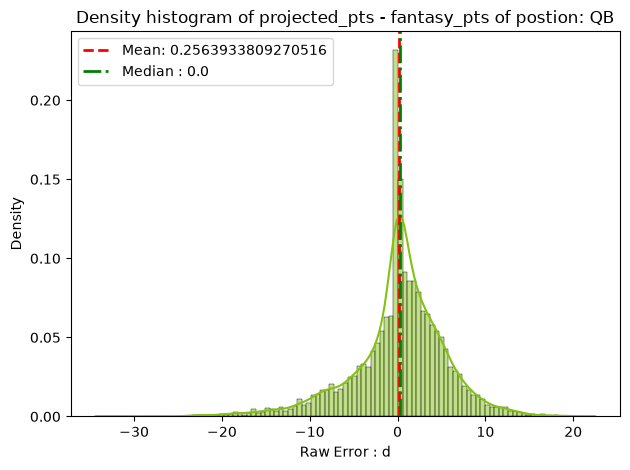

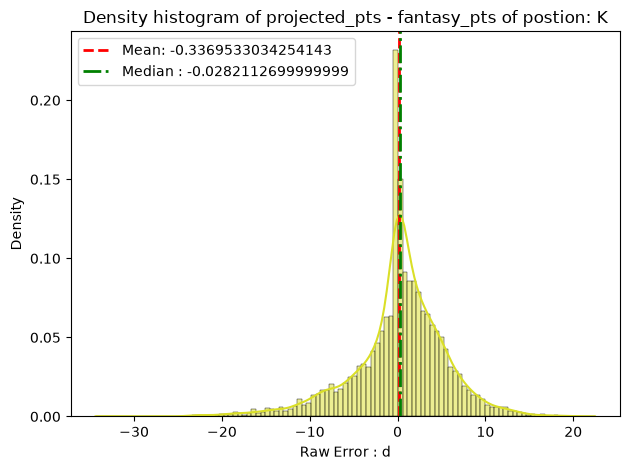

In [44]:
random.seed(78)
for pos in positions:
    generate_plot(df=df, pos = pos)

We can see that our distributions organized by position roughly follow the distribution of the overall distribution of raw differences without any major discrepencies.